# Strategy: the two models in strategy sims, with a one-time test evaluation per run

Loads the **move** and the **direction** model from `model_results/` (copied there from `model_search/`), scores tune, val_tune and test, and runs **`N_RUNS`** strategy optimisations of up to **`X_TRIALS`** trials each.

- **The strategy (A50):** the buy score is move × direction as a percentile of its tune distribution, with rebase exits and the fixed, causality-tested simulator.
- **Optimisation:** Optuna optimises **tune**; **val_tune** is sampled for early stopping and selects each run's parameters. Run i uses optimizer seed `OPTUNA_BASE_SEED + i`.
- **Test, once per run:** after each completed run, its selected parameters are simulated **once on test**, with the same configuration and the **same scoring function** as val (change `SCORE_MODE` and both change together). **Nothing is tuned or selected on test.**

**Results:**
1. All runs **ranked by the val score**, with the val score, test score, win rate (original entries and re-entries), total trades, the share of profitable, untraded and losing coins, trades per coin and average net profit per trade, all on the val set.
2. The **best val run's parameters**, and a plot (shown, not saved): for every parameter, the range holding **95% of the runs' chosen values**, the **best run's value**, and the **search bounds**, to show whether the optimiser pushes against a boundary.
3. The same table **ranked by the test score**, with the diagnostics on the test set, and the parameters of the best test run, for information. The honest result is the **test score of the best val run** (step 2): choosing by test would be selection on test.

**Splits:** tune / val_tune / test from `Dataset_creationV9`; the models' training splits are never used here.

**Output:** every file goes into `strategy_results/`. **Run All.** Resumable.

**Export (last cell):** writes `strategy_results/live_artifacts/` for the live pipeline: the two models, the tune reference distributions of the percentile scores, and the parameters of the **best val run** (`best_params.json`). Copy these files into `live_pipeline/artifacts/`.

In [8]:
# ============================================================================
# CONFIG — the strategy notebook
# ============================================================================
# Loads the two models (a MOVE and a DIRECTION .ubj) from MODEL_DIR, scores the
# tune / val_tune / test splits, and runs N_RUNS strategy optimisations of up to
# X_TRIALS trials each: the A50 strategy (buy score = move x direction as a tune
# percentile), rebase exits, the fixed (causality-tested) simulator. Optuna
# optimises TUNE; VAL_TUNE is sampled for early stopping and selects each run's
# parameters. After every completed run its selected parameters are evaluated ONCE
# on TEST, with the same scoring function — nothing is tuned or selected on test.
# Every file this notebook creates goes into OUT_DIR. Resumable.
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
import optuna.samplers
import json
import time
import gc
import warnings
from pathlib import Path
from numba import njit
import matplotlib.pyplot as plt

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.simplefilter('ignore', pd.errors.PerformanceWarning)

# ── INPUTS ───────────────────────────────────────────────────────────────────
MODEL_DIR = Path("model_results")               # exactly one move .ubj + one direction .ubj (+ their _params.json)
V9_SPLITS = Path("dataset_v9") / "splits"       # tune / val_tune / test
OHLCV_FOLDER = "processed_data"                 # cleaned OHLCV (data_cleaning.ipynb)

# ── OUTPUT: ONE FOLDER ───────────────────────────────────────────────────────
OUT_DIR = Path("strategy_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── RUNS ─────────────────────────────────────────────────────────────────────
N_RUNS = 50                                     # N: strategy optimisations (sampler seed OPTUNA_BASE_SEED + run)
X_TRIALS = 6000                                 # X: maximum trials per run
EARLY_STOPPING = True                           # True: a run may stop early once val stops improving
                                                # (never before MIN_TRIALS); False: always X_TRIALS trials
MIN_TRIALS = 500

# ── STRATEGY / SCORE ─────────────────────────────────────────────────────────
SIM_MODES = ['rebase']
SCORE_CAPITAL_CEILING_X = 10                    # score = mean over coins of min(final capital, 10 x start)
SCORE_LOG_FLOOR_X = 0.001
TRADING_START_HOURS = 12
SCORE_MODE = 'capped'                           # the SAME score is used for tune, val and test
TUNE_TAKE_PROFIT = True
ACTIVATION_BOUNDS = (0.10, 0.35)
ACTIVATION_THRESHOLD = 0.15
CONF_BOUNDS = (0.0, 1.0)
FIXED_PARAMS = {}
base_config = {
    'sol_price_usd': 130.0, 'initial_capital_usd': 20, 'slippage_pct': 0.015,
    'desired_price_impact_pct': 0.00333, 'target_fill_pct': 1,
    'trading_start_minutes': TRADING_START_HOURS * 60, 'data_folder': OHLCV_FOLDER,
    'exit_mode': 'rebase',
    'confidence_threshold': 0.8, 'activation_threshold': ACTIVATION_THRESHOLD,
    'stale_trade_minutes': 750, 'max_price_position_15m': 0.575, 'max_price_position_60m': 0.575,
    'reentry_threshold_pct': 0.10, 'loss_floor_pct': 0.25, 'loss_floor_consecutive_minutes': 3,
    'reentry_decay_rate': 0.0029, 'reentry_decay_start_minutes': 71,
}
# the search range of every tuned parameter (as in the objective) — for the boundary plot
PARAM_BOUNDS = {
    'confidence_threshold': CONF_BOUNDS, 'max_price_position_15m': (0.05, 0.95),
    'max_price_position_60m': (0.05, 0.95), 'activation_threshold': ACTIVATION_BOUNDS,
    'stale_trade_minutes': (60, 1440), 'reentry_threshold_pct': (0.005, 0.20), 'loss_floor_pct': (0.15, 0.40),
    'reentry_decay_rate': (0.0005, 0.01), 'reentry_decay_start_minutes': (20, 180),
    'loss_floor_consecutive_minutes': (2, 15),
}
MAX_TRIALS = X_TRIALS
N_TRIALS = min(MIN_TRIALS, X_TRIALS)            # early stopping is allowed from this trial on
CMAES_STARTUP_TRIALS = min(250, X_TRIALS)
EARLY_STOP_WARMUP = CMAES_STARTUP_TRIALS
VAL_EVAL_EVERY = 25
EARLY_STOP_PATIENCE_SAMPLES = 8 if EARLY_STOPPING else 10 ** 9
EARLY_STOP_TOL_FRAC, EARLY_STOP_TOL_MIN, EARLY_STOP_TOL_MIN_SAMPLES = 0.10, 0.001, 5
OPTUNA_BASE_SEED = 1
print(f"{N_RUNS} runs x up to {X_TRIALS} trials (early stopping {'on' if EARLY_STOPPING else 'off'}); "
      f"models from {MODEL_DIR}/  ->  {OUT_DIR}/")

50 runs x up to 6000 trials (early stopping on); models from model_results/  ->  strategy_results/


In [9]:
# ============================================================================
# MODELS + DATA
# ============================================================================
# The model type is read from each model's _params.json ('model_type') or, failing
# that, from its file name (move* / dir*). Predictions are cached per split.
# The buy score is the combo percentile within the TUNE distribution, for all splits.
# TEST — tune, val_tune and test share no coin with each other or with the models'
# training splits (train / val_train).
_KEYS = ['coin_id', 'timestamp']


def load_model(path):
    m = xgb.Booster()
    m.load_model(str(path))
    return m


def predict(model, df):
    f = list(model.feature_names)
    return model.predict(xgb.DMatrix(df[f], feature_names=f), iteration_range=(0, model.best_iteration + 1))


def to_percentile(values, reference):
    ref = np.sort(np.asarray(reference, dtype=np.float64))
    return np.clip(np.searchsorted(ref, np.asarray(values, dtype=np.float64), side='right') / len(ref), 1e-6, 1.0)


def _model_type(p):
    pj = p.with_name(p.stem + "_params.json")
    if pj.exists():
        t = json.load(open(pj)).get('model_type')
        if t in ('move', 'dir'):
            return t
    return 'move' if p.name.startswith('move') else ('dir' if p.name.startswith('dir') else None)


_found = {}
for p in sorted(MODEL_DIR.glob("*.ubj")):
    _found.setdefault(_model_type(p), []).append(p)
if len(_found.get('move', [])) != 1 or len(_found.get('dir', [])) != 1:
    raise RuntimeError(f"{MODEL_DIR}/ must hold exactly one move and one direction .ubj; found "
                       f"{ {k: [x.name for x in v] for k, v in _found.items()} }")
MODEL_FILES = {'move': _found['move'][0], 'dir': _found['dir'][0]}
MODELS = {k: load_model(p) for k, p in MODEL_FILES.items()}
for k, p in MODEL_FILES.items():
    print(f"  {k:<5} {p.name}  ({p.stat().st_size / 1024 / 1024:.2f} MB, {len(MODELS[k].feature_names)} features)")


def _coins(name):
    p = V9_SPLITS / f"{name}.csv"
    return set(pd.read_csv(p, usecols=['coin_id'])['coin_id'].astype(str).unique()) if p.exists() else set()


_sets = {s: _coins(s) for s in ('train', 'val_train', 'tune', 'val_tune', 'test')}
for a in ('tune', 'val_tune', 'test'):
    for b in ('train', 'val_train', 'tune', 'val_tune', 'test'):
        if a != b and _sets[a] & _sets[b]:
            raise RuntimeError(f"TEST failed: {a} and {b} share coins")
print("✓ TEST: tune / val_tune / test share no coins with each other or with train / val_train")

_tag = f"{MODEL_FILES['move'].stem}__{MODEL_FILES['dir'].stem}"
S = {}
for sp in ('tune', 'val_tune', 'test'):
    cp = OUT_DIR / f"scores_{sp}_{_tag}.pkl"
    if cp.exists():
        S[sp] = pd.read_pickle(cp)
        continue
    fr = pd.read_csv(V9_SPLITS / f"{sp}.csv")
    fr['coin_id'] = fr['coin_id'].astype(str)
    fr['timestamp'] = pd.to_datetime(fr['timestamp'], format='mixed', utc=True)
    out = fr[_KEYS + ['estimated_sol_1pct_impact', 'price_position_15m']].copy()
    out['price_position_60m'] = fr['price_position_1h'].to_numpy()
    out['raw_move'] = predict(MODELS['move'], fr)
    out['raw_dir'] = predict(MODELS['dir'], fr)
    out.to_pickle(cp)
    S[sp] = out
    del fr
    gc.collect()
_ref = S['tune']['raw_move'].to_numpy() * S['tune']['raw_dir'].to_numpy()
for sp in S:
    S[sp]['combo'] = to_percentile(S[sp]['raw_move'].to_numpy() * S[sp]['raw_dir'].to_numpy(), _ref)


def _read_ohlcv(coin):
    f = list(Path(OHLCV_FOLDER).glob(f"{coin}_ohlcv_cleaned.csv")) or \
        list(Path(OHLCV_FOLDER).glob(f"{coin.replace('_cleaned', '')}_ohlcv_cleaned.csv"))
    if not f:
        return None
    df = pd.read_csv(f[0])
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', utc=True, errors='coerce')
    return df[df['timestamp'].notna()].sort_values('timestamp').reset_index(drop=True)


ohlcv_data_cache = {}
for coin_name in pd.concat([S[sp]['coin_id'] for sp in S]).unique():
    o = _read_ohlcv(coin_name)
    if o is not None:
        for col in ['open', 'high', 'low', 'close']:
            o[col] = o[col] * base_config['sol_price_usd']
        ohlcv_data_cache[coin_name] = o
COINS = {sp: [c for c in S[sp]['coin_id'].unique() if c in ohlcv_data_cache] for sp in S}
COINS_TUNE, COINS_VAL = COINS['tune'], COINS['val_tune']
print(f"  coins: tune {len(COINS['tune'])}, val_tune {len(COINS['val_tune'])}, test {len(COINS['test'])}")

  move  move.ubj  (0.36 MB, 146 features)
  dir   direction.ubj  (0.07 MB, 146 features)
✓ TEST: tune / val_tune / test share no coins with each other or with train / val_train
  coins: tune 102, val_tune 102, test 100


In [10]:
# ============================================================================
# SIMULATION ENGINE — optuna_strategy_nopenalty.ipynb (no trades-per-coin
# penalty), with these additions, all OFF unless an experiment turns them on:
#   * confidence threshold can be FIXED (FIXED_PARAMS)        -> experiment 3
#   * SCORE_MODE 'coinfrac' = capped mean x coin fraction     -> experiment 4
#   * exit_mode 'stop' = stale / loss floor SELL              -> experiment 5
#   * take-profit tuned when TUNE_TAKE_PROFIT (else static)
#   * each trade records its exit reason; compute_score reports where the
#     P&L comes from (take-profit vs end-of-data vs stop exits)
# ============================================================================
import pandas as pd
import numpy as np
import xgboost as xgb
from pathlib import Path
import optuna
import gc
from numba import njit

# ========================================================================
# HELPER FUNCTION TO FORMAT DURATION
# ========================================================================

def format_duration(start_time, end_time):
    duration = end_time - start_time
    total_days = duration.total_seconds() / 86400
    months = int(total_days // 30)
    remaining_days = total_days - (months * 30)
    days = int(remaining_days)
    hours = int((remaining_days - days) * 24)
    parts = []
    if months > 0:
        parts.append(f"{months}mo")
    if days > 0 or months > 0:
        parts.append(f"{days}d")
    parts.append(f"{hours}h")
    return {
        'months': months, 'days': days, 'hours': hours,
        'total_days': total_days, 'formatted': " ".join(parts)
    }

# ========================================================================
# VECTORIZED PRE-COMPUTATION
# ========================================================================

def precompute_arrays(merged_df):
    n = len(merged_df)
    close_arr = merged_df['close'].values.astype(np.float64)

    return {
        'close': close_arr,
        'open': (merged_df['open'].values.astype(np.float64) if 'open' in merged_df else close_arr),
        'prediction': merged_df['prediction'].values.astype(np.float64),
        'liquidity': merged_df['estimated_sol_1pct_impact'].values.astype(np.float64),
        'price_position_15m': merged_df['price_position_15m'].values.astype(np.float64),
        'price_position_60m': merged_df['price_position_60m'].values.astype(np.float64),
        'n_rows': n,
    }

# ========================================================================
# CANDIDATE FINDER
# ------------------------------------------------------------------------
# A row fires as an entry candidate if:
#   prediction[i] >= confidence_threshold
#   AND price_position_15m[i] <= max_price_position_15m
#   AND price_position_60m[i] <= max_price_position_60m
# ========================================================================

@njit
def find_entry_candidates(prediction, price_position_15m, price_position_60m, n_rows,
                          conf_thresh, max_pp_15m, max_pp_60m):

    candidates = np.empty(n_rows, dtype=np.int64)
    count = 0

    for i in range(n_rows):
        if (prediction[i] >= conf_thresh and
                price_position_15m[i] <= max_pp_15m and
                price_position_60m[i] <= max_pp_60m):
            candidates[count] = i
            count += 1

    return candidates[:count]


# ========================================================================
# PRE-MERGE PREDICTIONS INTO OHLCV DATA
# ========================================================================

def precompute_merged_data(ohlcv_data_cache, test_df, xgb_model, feature_cols):
    """Pre-merge buy-model predictions into each coin's OHLCV timeline."""
    merged_cache = {}

    for coin_name, ohlcv_df in ohlcv_data_cache.items():
        coin_test = test_df[test_df['coin_id'] == coin_name].copy().reset_index(drop=True)
        if len(coin_test) == 0:
            continue

        X_test = coin_test[feature_cols].copy()
        X_test = X_test.loc[:, ~X_test.columns.duplicated()]
        X_test = X_test.apply(pd.to_numeric, errors='coerce')
        dtest = xgb.DMatrix(X_test, feature_names=feature_cols)
        predictions = xgb_model.predict(dtest, iteration_range=(0, xgb_model.best_iteration))
        coin_test['prediction'] = predictions

        merged_df = ohlcv_df.merge(
            coin_test[['timestamp', 'prediction', 'estimated_sol_1pct_impact',
                        'price_position_15m', 'price_position_60m']],
            on='timestamp', how='left'
        )
        merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

        merged_df['prediction'] = merged_df['prediction'].fillna(0)
        merged_df['estimated_sol_1pct_impact'] = merged_df['estimated_sol_1pct_impact'].fillna(0)
        merged_df['price_position_15m'] = merged_df['price_position_15m'].fillna(1.0)
        merged_df['price_position_60m'] = merged_df['price_position_60m'].fillna(1.0)

        sim_start = merged_df['timestamp'].iloc[0]
        sim_end = merged_df['timestamp'].iloc[-1]
        duration_info = format_duration(sim_start, sim_end)

        arrays = precompute_arrays(merged_df)

        merged_cache[coin_name] = {
            'arrays': arrays,
            'duration_info': duration_info,
        }

    return merged_cache

# ========================================================================
# WORST-CASE SCORE SENTINEL
# ------------------------------------------------------------------------
# Returned by degenerate trials (no simulable coins). The score is mean capped
# final capital in dollars, so $0 — every coin wiped out — is genuinely the floor.
# ========================================================================

WORST_SCORE = 0.0

# ========================================================================
# REASON CODES FOR NUMBA
# ========================================================================

REASON_ACTIVATED = 0
REASON_END_OF_DATA = 2
REASON_STALE_EXIT = 3
REASON_REACHED_BOUND = 4
REASON_LOSS_FLOOR_ARMED = 5
REASON_LOSS_FLOOR_RECOVERY = 6
REASON_SIGNAL_EXIT = 7
REASON_TIME_EXIT = 8

# ========================================================================
# FAST TRADE SIMULATION
# ========================================================================

@njit
def trail_exit(arr_close, start_idx, n_rows, trail_pct, max_minutes):
    """Trailing phase after the take-profit is reached at start_idx: follow the
    running high of the close and exit at the first minute the close is
    trail_pct below it, after max_minutes, or at the end of the data.
    max_minutes = 0 exits at start_idx (= the plain take-profit)."""
    peak = arr_close[start_idx]
    end = min(n_rows - 1, start_idx + max_minutes)
    for j in range(start_idx + 1, end + 1):
        c = arr_close[j]
        if c > peak:
            peak = c
        if c <= peak * (1.0 - trail_pct):
            return j
    return end


@njit
def hold_exit(arr_close, score, start_idx, n_rows, h, max_minutes, trail_pct):
    """SIGNAL HOLD after the take-profit is reached at start_idx: keep holding while
    score >= h; exit at the first minute the score drops below h, the close falls
    trail_pct below its running high, max_minutes have passed, or the data ends.
    If the score is already below h at start_idx: exit there (= the take-profit)."""
    if score[start_idx] < h:
        return start_idx
    peak = arr_close[start_idx]
    end = min(n_rows - 1, start_idx + max_minutes)
    for j in range(start_idx + 1, end + 1):
        c = arr_close[j]
        if c > peak:
            peak = c
        if score[j] < h or c <= peak * (1.0 - trail_pct):
            return j
    return end


@njit
def signal_exit_idx(dir_s, move_s, start, stop, x_dir, z_move):
    """first minute in [start, stop) where the direction score < x_dir or the move
    score < z_move; -1 if none."""
    for j in range(start, stop):
        if dir_s[j] < x_dir or move_s[j] < z_move:
            return j
    return -1


@njit
def simulate_trade(arr_close, n_rows,
                   entry_idx, entry_price,
                   act_thresh, stale_minutes, loss_floor_pct,
                   start_idx, max_exit_idx, stale_active,
                   loss_floor_mode, n_consec_required,
                   max_price_seen_init):
    """Run from start_idx up to (but excluding) min(n_rows, max_exit_idx).

    Returns (exit_idx, reason, max_price_seen_final). The final max_price
    is returned so callers can resume the trade across multiple phase calls
    without losing the running high since entry.

    Priority at each minute: activation > loss-floor > stale.

    `stale_active=0` disables the stale check (used during the post-stale
    race phase where stale has already been crossed once).

    `loss_floor_mode`:
      0 — ignore the loss floor entirely (used in stale-race scan).
      1 — arm-watch (Phase 1): count consecutive minutes where
          arr_close[i] <= entry_price*(1 - floor). When the count reaches
          n_consec_required, return REASON_LOSS_FLOOR_ARMED. A minute
          above the floor resets the count.
      2 — recovery-watch (during loss-floor race): the FIRST minute where
          arr_close[i] > entry_price*(1 - floor) returns
          REASON_LOSS_FLOOR_RECOVERY.

    `max_exit_idx`: if the loop reaches this index without activating,
    return REASON_REACHED_BOUND. Pass n_rows for no bound.

    `max_price_seen_init`: pass -1.0 for fresh start (any close above -1.0
    becomes the new max). Pass the previously-returned max when resuming.
    """
    end = max_exit_idx if max_exit_idx < n_rows else n_rows
    if end <= start_idx:
        if end == n_rows:
            return n_rows - 1, REASON_END_OF_DATA, max_price_seen_init
        return start_idx - 1, REASON_REACHED_BOUND, max_price_seen_init

    max_price_seen = max_price_seen_init
    below_floor_count = 0

    for i in range(start_idx, end):
        minutes_held = i - entry_idx
        c_close = arr_close[i]

        if c_close > max_price_seen:
            max_price_seen = c_close

        # 1) Sell-threshold (highest priority)
        if max_price_seen >= entry_price * (1.0 + act_thresh):
            return i, REASON_ACTIVATED, max_price_seen

        # 2) Loss-floor handling
        if loss_floor_mode != 0:
            floor_price = entry_price * (1.0 - loss_floor_pct)

            if loss_floor_mode == 1:
                if c_close <= floor_price:
                    below_floor_count += 1
                    if below_floor_count >= n_consec_required:
                        return i, REASON_LOSS_FLOOR_ARMED, max_price_seen
                else:
                    below_floor_count = 0
            else:  # loss_floor_mode == 2: recovery-watch
                if c_close > floor_price:
                    return i, REASON_LOSS_FLOOR_RECOVERY, max_price_seen

        # 3) Stale (lowest priority)
        if stale_active:
            if minutes_held > stale_minutes:
                return i, REASON_STALE_EXIT, max_price_seen

    if end == n_rows:
        return n_rows - 1, REASON_END_OF_DATA, max_price_seen
    return end - 1, REASON_REACHED_BOUND, max_price_seen

# ========================================================================
# SIMULATION FUNCTION
# ========================================================================

def simulate_coin(coin_name, config, merged_cache):
    if coin_name not in merged_cache:
        return None

    cached = merged_cache[coin_name]
    arrays = cached['arrays']
    duration_info = cached['duration_info']

    candidates = find_entry_candidates(
        arrays['prediction'], arrays['price_position_15m'], arrays['price_position_60m'],
        arrays['n_rows'],
        config['confidence_threshold'],
        config['max_price_position_15m'],
        config['max_price_position_60m']
    )

    if len(candidates) == 0:
        return {
            'coin': coin_name, 'n_trades': 0,
            'n_reentries': 0,
            'n_original_wins': 0, 'n_original_losses': 0,
            'n_reentry_wins': 0, 'n_reentry_losses': 0,
            'n_loss_floor_arms': 0, 'n_loss_floor_recoveries': 0,
            'final_capital': config['initial_capital_usd'],
            'pnl_usd': 0, 'pnl_pct': 0, 'total_fees_usd': 0,
            'duration_days': duration_info['total_days'],
            'trades_per_day': 0,
            'trades': [],
        }

    capital = config['initial_capital_usd']
    total_fees = 0.0
    trades = []

    arr_close = arrays['close']
    arr_liquidity = arrays['liquidity']
    n_rows = arrays['n_rows']
    # EXECUTION CHECK (2026-11, off by default): 'fill_next' = 'open' / 'close' fills
    # EVERY entry and exit at the next minute's open / close instead of the signal
    # minute's close; 'se_fill_open' does that for signal exits only.
    arr_open = arrays.get('open', arr_close)
    _fill_next = str(config.get('fill_next', '') or '')
    _se_fill_open = float(config.get('se_fill_open', 0.0)) > 0.5

    slippage_pct = config['slippage_pct']
    fill_pct = config['target_fill_pct']

    # Strategy parameters.
    g_act_thresh = float(config['activation_threshold'])
    g_stale      = float(config['stale_trade_minutes'])
    g_reentry    = float(config['reentry_threshold_pct'])
    g_loss_floor = float(config['loss_floor_pct'])
    loss_floor_consec = int(config['loss_floor_consecutive_minutes'])

    desired_price_impact_pct = config['desired_price_impact_pct']
    sol_price_usd = config['sol_price_usd']
    initial_capital = config['initial_capital_usd']
    g_trading_start = int(config.get('trading_start_minutes', 0))   # no entries before this minute

    reentry_decay_rate_per_min = config['reentry_decay_rate']
    reentry_decay_start = float(config['reentry_decay_start_minutes'])
    # EXPERIMENT 5: exit_mode 'stop' SELLS when the stale timer or the loss floor
    # fires (instead of re-basing the entry and holding). 'rebase' = original.
    g_exit_mode_stop = (config.get('exit_mode', 'rebase') == 'stop')

    last_sell_close = -1.0
    last_sell_idx = -1

    # PER-TIER trade parameters (tier strategy, 2026-11): if the view carries a
    # per-minute 'tier_idx' and the config per-tier lists, every trade takes its
    # take-profit / stale / loss floor from the tier of its ENTRY minute (kept for
    # the trade's whole life, incl. rebases), and the re-entry threshold from the
    # tier of the candidate minute. Without them nothing changes.
    _tier_arr = arrays.get('tier_idx')
    _per_tier = _tier_arr is not None and 'tier_act' in config
    if _per_tier:
        _t_act = [float(x) for x in config['tier_act']]
        _t_stale = [float(x) for x in config['tier_stale']]
        _t_lf = [float(x) for x in config['tier_lf']]
        _t_re = [float(x) for x in config['tier_reentry']]

    # MODEL-DRIVEN STRATEGY OPTIONS (strategies, 2026-11); each is off unless its keys
    # are in the config. The view supplies per-minute 'combo_t', 'dir_t', 'move_t'.
    #   ts_*  take-profit / stale / loss floor scaled by the combo at entry (linear
    #         between combo 0.5 -> *_lo and combo 1.0 -> *_hi)
    #   se_*  signal exit: sell at the first minute (after se_min_hold) the direction
    #         score < se_dir or the move score < se_move; se_tp_off disables the take-profit
    #   sh_*  signal hold: at the take-profit keep holding while the combo >= sh_h
    #         (max sh_max minutes, or sh_trail below the running high)
    _ts_on = 'ts_tp_lo' in config
    if _ts_on:
        _ts = [float(config[k]) for k in ('ts_tp_lo', 'ts_tp_hi', 'ts_st_lo', 'ts_st_hi', 'ts_lf_lo', 'ts_lf_hi')]
    _se_on = 'se_dir' in config
    if _se_on:
        _se_dir, _se_move = float(config['se_dir']), float(config['se_move'])
        _se_min = int(config.get('se_min_hold', 0))
        _se_delay = int(config.get('se_delay', 0))     # diagnostic: execute the signal exit d minutes later
        if float(config.get('se_tp_off', 0.0)) > 0.5:
            g_act_thresh = 100.0
    _te_on = 'te_minutes' in config               # TIME EXIT: sell at market te_minutes after the entry
    _te_min = int(config.get('te_minutes', 0))
    _sh_on = 'sh_h' in config
    if _sh_on:
        _sh_h, _sh_max, _sh_trail = float(config['sh_h']), int(config['sh_max']), float(config['sh_trail'])
    _combo_t = arrays.get('combo_t')
    _dir_t = arrays.get('dir_t')
    _move_t = arrays.get('move_t')

    _trail_on = 'trail_pct' in config
    _trail_pct = float(config.get('trail_pct', 0.0))
    _trail_keep = float(config.get('trail_keep', 1.0))
    _trail_max = int(config.get('trail_max_minutes', 0))

    def passes_reentry_threshold(idx):
        if last_sell_close <= 0:
            return True
        re_thresh = _t_re[int(_tier_arr[idx])] if _per_tier else g_reentry
        minutes_since_sell = float(idx - last_sell_idx)
        if minutes_since_sell > reentry_decay_start:
            relaxation = (minutes_since_sell - reentry_decay_start) * reentry_decay_rate_per_min
            effective_reentry = re_thresh - relaxation
            if effective_reentry < -5.0:
                return True
            return arr_close[idx] <= last_sell_close * (1.0 - effective_reentry)
        else:
            return arr_close[idx] <= last_sell_close * (1.0 - re_thresh)

    c_ptr = 0
    n_candidates = len(candidates)

    while c_ptr < n_candidates:
        entry_idx = candidates[c_ptr]
        c_ptr += 1

        if entry_idx < g_trading_start:      # can't trade until TRADING_START_HOURS after listing
            continue
        if entry_idx <= last_sell_idx:
            continue
        if not passes_reentry_threshold(entry_idx):
            continue

        if _per_tier:
            _ti = int(_tier_arr[entry_idx])
            g_act_thresh, g_stale, g_loss_floor = _t_act[_ti], _t_stale[_ti], _t_lf[_ti]
        if _ts_on:
            _f = min(max((_combo_t[entry_idx] - 0.5) / 0.5, 0.0), 1.0)
            g_act_thresh = _ts[0] + (_ts[1] - _ts[0]) * _f
            g_stale = _ts[2] + (_ts[3] - _ts[2]) * _f
            g_loss_floor = _ts[4] + (_ts[5] - _ts[4]) * _f
        if _fill_next and entry_idx + 1 < n_rows:
            entry_idx = entry_idx + 1
            entry_price = (arr_open[entry_idx] if _fill_next == 'open' else arr_close[entry_idx]) * (1.0 + slippage_pct)
        else:
            entry_price = arr_close[entry_idx] * (1.0 + slippage_pct)
        available_capital = capital

        liq = arr_liquidity[entry_idx]
        if not np.isnan(liq) and liq > 0:
            sol_needed = liq * (desired_price_impact_pct * 100)
            max_usd = sol_needed * sol_price_usd
            amount = min(available_capital, max_usd)
            cap_active = True
        else:
            max_usd = np.inf                 # no liquidity value -> cap NOT applied (full capital)
            amount = available_capital
            cap_active = False
        cap_bound = cap_active and (max_usd < available_capital - 1e-9)   # did the cap actually limit the buy?

        if amount <= 0:
            continue

        shares = amount / entry_price
        capital -= amount

        buy_fee = shares * arr_close[entry_idx] * slippage_pct
        total_fees += buy_fee

        original_entry_price = entry_price
        original_entry_idx = entry_idx

        current_entry_idx = entry_idx
        current_entry_price = entry_price
        n_reentries = 0
        n_loss_floor_arms_this_trade = 0
        n_loss_floor_recoveries_this_trade = 0
        last_reentry_start_price = 0.0  # only used when n_reentries > 0
        final_reason_code = REASON_END_OF_DATA
        final_exit_idx = n_rows - 1

        # Per-segment state. phase1_start moves forward after a loss-floor
        # recovery so we don't re-scan minutes that already armed/recovered.
        # max_price_carry preserves the running high across phase boundaries
        # within the same segment; it resets to -1.0 on each re-entry.
        phase1_start = current_entry_idx + 1
        max_price_carry = -1.0

        while True:
            # ── Phase 1 (NORMAL) ───────────────────────────────────────
            # Stale active + loss-floor arm-watch. Activation wins ties.
            exit_idx, reason_code, max_price_carry = simulate_trade(
                arr_close, n_rows,
                current_entry_idx, current_entry_price,
                g_act_thresh, g_stale, g_loss_floor,
                phase1_start, n_rows, 1,
                1, loss_floor_consec,
                max_price_carry
            )

            if reason_code == REASON_ACTIVATED or reason_code == REASON_END_OF_DATA:
                final_exit_idx = exit_idx
                final_reason_code = reason_code
                break

            if g_exit_mode_stop:
                # stale / loss floor fired -> SELL at this bar's close (real stop)
                final_exit_idx = exit_idx
                final_reason_code = reason_code
                break

            # Find next qualifying re-entry candidate past exit_idx.
            # Same scan logic for both stale-race and loss-floor race:
            # advance c_ptr past anything ≤ exit_idx or failing the
            # re-entry threshold (those are permanently consumed,
            # matching prior behavior). Stop at the first qualifier;
            # don't bump c_ptr past it unless we actually take it.
            next_re_idx = -1
            qualifier_c_ptr = -1
            scan_ptr = c_ptr
            while scan_ptr < n_candidates:
                cand = candidates[scan_ptr]
                if cand <= exit_idx:
                    scan_ptr += 1
                    continue
                if not passes_reentry_threshold(cand):
                    scan_ptr += 1
                    continue
                next_re_idx = cand
                qualifier_c_ptr = scan_ptr
                break
            c_ptr = scan_ptr
            race_bound = n_rows if next_re_idx == -1 else next_re_idx

            if reason_code == REASON_STALE_EXIT:
                # ── Stale race (terminal) ──────────────────────────────
                # Stale fires once and latches; race runs with stale off
                # and loss-floor ignored. Either sell wins (finalize),
                # the qualifier wins (re-enter), or end-of-data.
                race_exit_idx, race_reason, _ = simulate_trade(
                    arr_close, n_rows,
                    current_entry_idx, current_entry_price,
                    g_act_thresh, g_stale, g_loss_floor,
                    exit_idx + 1, race_bound, 0,
                    0, loss_floor_consec,
                    max_price_carry
                )
                if race_reason == REASON_ACTIVATED or race_reason == REASON_END_OF_DATA:
                    final_exit_idx = race_exit_idx
                    final_reason_code = race_reason
                    break
                # REASON_REACHED_BOUND — take the qualifier
                c_ptr = qualifier_c_ptr + 1
                current_entry_idx = next_re_idx
                current_entry_price = arr_close[next_re_idx]
                last_reentry_start_price = arr_close[next_re_idx]
                n_reentries += 1
                phase1_start = current_entry_idx + 1
                max_price_carry = -1.0
                continue

            # ── Loss-floor race (revertible) ───────────────────────────
            # Stale still ticks; recovery (1 minute above floor) disarms
            # and resumes Phase 1 from the recovery minute. Possible
            # outcomes:
            #   ACTIVATED       → finalize
            #   END_OF_DATA     → finalize
            #   REACHED_BOUND   → qualifier wins; re-enter
            #   RECOVERY        → resume Phase 1 from race_exit_idx+1
            #   STALE_EXIT      → stale dominates; run terminal stale
            #                     race from race_exit_idx onward
            n_loss_floor_arms_this_trade += 1
            race_exit_idx, race_reason, race_max_price = simulate_trade(
                arr_close, n_rows,
                current_entry_idx, current_entry_price,
                g_act_thresh, g_stale, g_loss_floor,
                exit_idx + 1, race_bound, 1,
                2, loss_floor_consec,
                max_price_carry
            )

            if race_reason == REASON_ACTIVATED or race_reason == REASON_END_OF_DATA:
                final_exit_idx = race_exit_idx
                final_reason_code = race_reason
                break

            if race_reason == REASON_REACHED_BOUND:
                c_ptr = qualifier_c_ptr + 1
                current_entry_idx = next_re_idx
                current_entry_price = arr_close[next_re_idx]
                last_reentry_start_price = arr_close[next_re_idx]
                n_reentries += 1
                phase1_start = current_entry_idx + 1
                max_price_carry = -1.0
                continue

            if race_reason == REASON_LOSS_FLOOR_RECOVERY:
                # Resume Phase 1 from the minute AFTER recovery. Keep the
                # same segment (no re-entry happened); preserve max_price.
                n_loss_floor_recoveries_this_trade += 1
                phase1_start = race_exit_idx + 1
                max_price_carry = race_max_price
                continue

            # race_reason == REASON_STALE_EXIT — stale wins during loss-floor
            # race. Run a terminal stale-race from this point. The qualifier
            # we already located stays valid (race_exit_idx < race_bound).
            sr_exit_idx, sr_reason, _ = simulate_trade(
                arr_close, n_rows,
                current_entry_idx, current_entry_price,
                g_act_thresh, g_stale, g_loss_floor,
                race_exit_idx + 1, race_bound, 0,
                0, loss_floor_consec,
                race_max_price
            )
            if sr_reason == REASON_ACTIVATED or sr_reason == REASON_END_OF_DATA:
                final_exit_idx = sr_exit_idx
                final_reason_code = sr_reason
                break
            # REASON_REACHED_BOUND
            c_ptr = qualifier_c_ptr + 1
            current_entry_idx = next_re_idx
            current_entry_price = arr_close[next_re_idx]
            last_reentry_start_price = arr_close[next_re_idx]
            n_reentries += 1
            phase1_start = current_entry_idx + 1
            max_price_carry = -1.0
            # continue loops back to Phase 1

        # ---- EXIT FILL --------------------------------------------------------
        # An ACTIVATED exit fires on the first bar whose close is >= the activation
        # target, and the fill is booked at that bar's close. This matches live
        # behaviour: the decision is taken once the bar has closed, using only that
        # bar's close, and the order goes out ~5s later. Drift over those 5s is not
        # modelled (add it with the price WebSocket).
        #
        # overshoot_ratio records how far past the target that close actually was, so
        # you can see how much of the PnL depends on prices a live fill may not get.
        # LET WINNERS RUN (2026-11): with 'trail_pct' in the config, a position whose
        # take-profit is reached is not sold there: a share (1 - trail_keep) is sold at
        # the take-profit close, the rest follows the price and is sold trail_pct below
        # its running high (or after trail_max_minutes / at the end of the data). The
        # position counts as closed at the trailing exit. Without 'trail_pct' nothing changes.
        _truncated = False
        if _te_on and original_entry_idx + _te_min < final_exit_idx:
            final_exit_idx = original_entry_idx + _te_min
            final_reason_code = REASON_TIME_EXIT
            _truncated = True
        if _se_on:                                    # a model sell signal before the planned exit wins
            _sx = signal_exit_idx(_dir_t, _move_t, original_entry_idx + 1 + _se_min, final_exit_idx, _se_dir, _se_move)
            if _sx >= 0 and _sx + _se_delay < final_exit_idx:
                final_exit_idx = min(_sx + _se_delay, n_rows - 1)
                final_reason_code = REASON_SIGNAL_EXIT
                _truncated = True
        if _sh_on and final_reason_code == REASON_ACTIVATED:
            final_exit_idx = hold_exit(arr_close, _combo_t, final_exit_idx, n_rows, _sh_h, _sh_max, _sh_trail)
        _tp_close = arr_close[final_exit_idx]
        _blend_close = -1.0
        if _trail_on and final_reason_code == REASON_ACTIVATED:
            _tx = trail_exit(arr_close, final_exit_idx, n_rows, _trail_pct, _trail_max)
            _blend_close = (1.0 - _trail_keep) * _tp_close + _trail_keep * arr_close[_tx]
            final_exit_idx = _tx
        exit_close = arr_close[final_exit_idx] if _blend_close < 0 else _blend_close
        if _blend_close < 0 and (_fill_next or (_se_fill_open and final_reason_code == REASON_SIGNAL_EXIT)):
            _k = min(final_exit_idx + 1, n_rows - 1)
            exit_close = arr_close[_k] if _fill_next == 'close' else arr_open[_k]
            final_exit_idx = _k
        # LOOK-AHEAD FIX (2026-11-15): the trade above was played out to its take-profit /
        # end of data BEFORE the signal / time exit moved its end earlier; that imaginary
        # continuation advanced the candidate pointer (rebase / race scans). Rewind it to
        # the first candidate after the REAL exit, so nothing of the continuation is used.
        # legacy_cptr = True reproduces the old (biased) behaviour, for the tests only.
        if _truncated and not bool(config.get('legacy_cptr', False)):
            c_ptr = int(np.searchsorted(candidates, final_exit_idx, side='right'))
        if final_reason_code == REASON_ACTIVATED:
            _target = current_entry_price * (1.0 + g_act_thresh)
            overshoot_ratio = (exit_close / _target) if _target > 0 else np.nan
        else:
            overshoot_ratio = np.nan

        pnl_pct_raw = (exit_close - original_entry_price) / original_entry_price

        if pnl_pct_raw >= 0.0:
            realized_pct = pnl_pct_raw * fill_pct
        else:
            realized_pct = pnl_pct_raw * (2.0 - fill_pct)

        actual_price = original_entry_price * (1.0 + realized_pct)
        exit_price = actual_price * (1.0 - slippage_pct)

        sell_fee = shares * actual_price * slippage_pct
        total_fees += sell_fee

        proceeds = shares * exit_price
        capital += proceeds

        pnl_pct = (exit_price - original_entry_price) / original_entry_price
        pnl_usd = shares * (exit_price - original_entry_price)

        # ---- Per-segment win/loss accounting -----------------------------
        # A "segment" is the original entry plus each re-entry. Any segment
        # that triggered a re-entry counts as a loss (regardless of price).
        # The FINAL segment is win/loss based on the realized exit price vs
        # that segment's own start price.
        if n_reentries == 0:
            # Original IS the final segment
            if exit_price > original_entry_price:
                seg_orig_win, seg_orig_loss = 1, 0
            else:
                seg_orig_win, seg_orig_loss = 0, 1
            seg_re_win, seg_re_loss = 0, 0
        else:
            # Original re-entered -> automatic loss
            seg_orig_win, seg_orig_loss = 0, 1
            # Re-entries: all but the last triggered another re-entry -> losses;
            # the last re-entry is win/loss based on realized exit vs its start.
            if exit_price > last_reentry_start_price:
                seg_re_win = 1
                seg_re_loss = n_reentries - 1
            else:
                seg_re_win = 0
                seg_re_loss = n_reentries

        trades.append({
            'entry_idx': original_entry_idx,
            'exit_idx': final_exit_idx,
            'pnl_pct': pnl_pct,
            'pnl_usd': pnl_usd,
            'minutes_held': final_exit_idx - original_entry_idx,
            'n_reentries': n_reentries,
            'n_loss_floor_arms': n_loss_floor_arms_this_trade,
            'n_loss_floor_recoveries': n_loss_floor_recoveries_this_trade,
            'original_win': seg_orig_win,
            'original_loss': seg_orig_loss,
            'activated': final_reason_code == REASON_ACTIVATED,
            'exit_reason': int(final_reason_code),
            'overshoot_ratio': overshoot_ratio,
            'reentry_wins': seg_re_win,
            'reentry_losses': seg_re_loss,
            # --- fill / liquidity-cap diagnostics (from the ORIGINAL entry) ---
            'liq': liq,
            'available_capital': available_capital,
            'max_usd': max_usd,
            'amount': amount,
            # fraction of capital actually deployed. capital_after = capital_before*(1 + fill_frac*pnl_pct),
            # so log(final/initial) == sum of log(1 + fill_frac*pnl_pct) over trades, exactly.
            'fill_frac': (amount / available_capital) if available_capital > 0 else 0.0,
            'cap_active': cap_active,
            'cap_bound': cap_bound,
        })

        last_sell_close = arr_close[final_exit_idx]
        last_sell_idx = final_exit_idx

    trades_per_day = len(trades) / duration_info['total_days'] if duration_info['total_days'] > 0 else 0

    # Per-coin aggregates for the new scoring
    n_reentries_total = sum(t['n_reentries'] for t in trades)
    n_orig_win = sum(t['original_win'] for t in trades)
    n_orig_loss = sum(t['original_loss'] for t in trades)
    n_re_win = sum(t['reentry_wins'] for t in trades)
    n_re_loss = sum(t['reentry_losses'] for t in trades)
    n_lf_arms_total = sum(t['n_loss_floor_arms'] for t in trades)
    n_lf_recoveries_total = sum(t['n_loss_floor_recoveries'] for t in trades)

    return {
        'coin': coin_name,
        'n_trades': len(trades),
        'n_reentries': n_reentries_total,
        'n_original_wins': n_orig_win,
        'n_original_losses': n_orig_loss,
        'n_reentry_wins': n_re_win,
        'n_reentry_losses': n_re_loss,
        'n_loss_floor_arms': n_lf_arms_total,
        'n_loss_floor_recoveries': n_lf_recoveries_total,
        'final_capital': capital,
        'pnl_usd': capital - initial_capital,
        'pnl_pct': (capital - initial_capital) / initial_capital * 100,
        'total_fees_usd': total_fees,
        'duration_days': duration_info['total_days'],
        'trades_per_day': trades_per_day,
        'trades': trades,
    }

# ========================================================================
# SCORE  (mean per-coin capped final capital, in dollars)
# ========================================================================

def compute_score(all_results):
    """
    score = mean( min(final_capital, ceiling) )        (NO trades-per-coin penalty)

    Every coin gets its own independent initial_capital_usd, so total P&L across a set is
    exactly n * (arithmetic mean of final capital - initial). The ARITHMETIC mean is therefore
    the quantity that translates to money; a geometric mean would only be right if one account
    compounded through the coins sequentially. Per-coin downside is also bounded — a coin can
    cost you at most its allocation — so a wipeout is worth exactly -initial, no worse.

    The mean is winsorised at SCORE_CAPITAL_CEILING_X x starting capital first. That is a pure
    bias-for-variance trade: the raw arithmetic mean is the right objective but a dreadful
    ESTIMATOR on ~70 coins, because the top 1-3 coins can be 60-99% of total P&L and which coins
    those are does not transfer between splits. Winsorising biases the estimate down in exchange
    for one that generalises. Pick the ceiling deliberately — see SCORE_CAPITAL_CEILING_X.

    mean_log_return / geo_mean_x are still returned as diagnostics, they just no longer drive
    the score. The win rates are diagnostics only.

    Baseline is the starting capital, NOT zero: a coin that never trades scores exactly
    initial_capital_usd, so abstaining is worth $initial and still beats any losing config.
    NO-PENALTY VARIANT: nothing stops the optimiser from buying that. Abstention scores
    exactly $initial here. trades_per_coin is still computed and reported (diagnostic only),
    and 'tpc_penalty' is always 0.0 so downstream tables keep their columns.
    Returns (score, diagnostics).
    """
    if not all_results:
        return WORST_SCORE, {'median_final_capital': 0.0, 'avg_final_capital': 0.0, 'avg_capped_capital': 0.0,
                     'win_rate_originals': 1.0, 'win_rate_reentries': 1.0,
                     'total_trades': 0,
                     'n_unprofitable': 0,
                     'pct_profitable': 0.0, 'pct_untraded': 0.0, 'pct_unprofitable': 0.0,
                     'median_tpc': 0.0, 'n_scored_coins': 0,
                     'mean_log_return': WORST_SCORE, 'median_log_return': WORST_SCORE,
                     'trades_per_coin': 0.0, 'tpc_penalty': 0.0, 'total_pnl_usd': 0.0,
                     'geo_mean_x': 0.0, 'n_log_floored': 0, 'n_log_ceiled': 0,
                     'rebased_mean_log': float('nan'), 'n_rebased_harvests': 0}

    initial = globals().get('base_config', {}).get('initial_capital_usd', 20)
    _ceil_x = globals().get('SCORE_CAPITAL_CEILING_X', 10)
    ceiling = (_ceil_x * initial) if _ceil_x else float('inf')   # None/0 disables the ceiling
    log_floor_usd = globals().get('SCORE_LOG_FLOOR_X', 0.001) * initial

    caps = [r['final_capital'] for r in all_results]

    # ---- THE SCORE: mean per-coin log growth factor, clipped both ends ----
    # Floor/ceiling are for the log DIAGNOSTICS only; the score uses avg_capped below.
    log_rets = [np.log(min(max(c, log_floor_usd), ceiling) / initial) for c in caps]
    mean_log = float(np.mean(log_rets))
    median_log = float(np.median(log_rets))
    geo_mean_x = float(np.exp(mean_log))
    n_log_floored = int(sum(1 for c in caps if c < log_floor_usd))
    n_log_ceiled = int(sum(1 for c in caps if c > ceiling))

    # ---- RE-BASED LEG -----------------------------------------------------
    # A harvest (ACTIVATED exit) whose trade re-based at least once. pnl_pct is measured
    # vs the ORIGINAL entry while activation fires off the RE-BASED entry, so these book
    # losses. capital_after = capital_before*(1 + fill_frac*pnl_pct), so log1p(fill*pnl)
    # is each trade's exact contribution — the mean is what the leg costs per trade.
    # Log, not the arithmetic mean of pnl_pct: the -90%+ tail is what drives compounding
    # and an arithmetic mean under-weights it.
    _rebased = [t for r in all_results for t in r['trades']
                if t['activated'] and t['n_reentries'] > 0]
    n_rebased_harvests = len(_rebased)
    rebased_mean_log = (float(np.mean([np.log1p(t['fill_frac'] * t['pnl_pct']) for t in _rebased]))
                        if _rebased else float('nan'))   # NaN, not 0.0 — 0.0 would read as "no loss"

    # ---- capital ----------------------------------------------------------
    # avg_capped IS the score. avg_final_capital is the uncapped arithmetic mean, i.e.
    # true P&L per coin + initial — compare the two to see how much the ceiling is
    # discarding on each set.
    capped = [min(c, ceiling) for c in caps]
    avg_capped = float(np.mean(capped))
    avg_final_capital = float(np.mean(caps))
    median_final_capital = float(np.median(caps))
    total_pnl_usd = float(sum(c - initial for c in caps))

    ow = sum(r['n_original_wins'] for r in all_results)
    ol = sum(r['n_original_losses'] for r in all_results)
    rw = sum(r['n_reentry_wins'] for r in all_results)
    rl = sum(r['n_reentry_losses'] for r in all_results)
    wr_orig = (ow / (ow + ol)) if (ow + ol) > 0 else 1.0
    wr_re   = (rw / (rw + rl)) if (rw + rl) > 0 else 1.0

    tpc_all = [r['n_trades'] for r in all_results]
    median_tpc = float(np.median(tpc_all)) if tpc_all else 0.0
    total_trades = int(sum(r['n_trades'] for r in all_results))

    # ---- NO ANTI-ABSTENTION PENALTY (this variant) -------------------------
    # The original notebook subtracted a trades-per-coin penalty here. It is removed:
    # the score is the plain capped mean. trades_per_coin is kept as a diagnostic so
    # the two variants can be compared on how much each one actually trades.
    trades_per_coin = total_trades / len(all_results) if all_results else 0.0
    tpc_penalty = 0.0                       # always zero in this variant

    score = avg_capped

    n = len(all_results)
    n_profitable = sum(1 for r in all_results if r.get('pnl_usd', 0.0) > 0)
    n_untraded = sum(1 for r in all_results if r['n_trades'] == 0)
    n_unprofitable = sum(1 for r in all_results if r['n_trades'] > 0 and r.get('pnl_usd', 0.0) <= 0)
    pct_profitable = 100.0 * n_profitable / n if n else 0.0
    pct_untraded = 100.0 * n_untraded / n if n else 0.0
    pct_unprofitable = 100.0 * n_unprofitable / n if n else 0.0

    # ---- EXPERIMENT 4: alternative score ------------------------------------
    # coin_frac = (profitable coins + 0.5 * untraded coins) / coins
    # SCORE_MODE 'capped'   -> score = avg_capped               (default)
    # SCORE_MODE 'coinfrac' -> score = avg_capped * coin_frac
    # Both are always reported.
    coin_frac = (n_profitable + 0.5 * n_untraded) / n if n else 0.0
    score_capped = avg_capped
    score_coinfrac = avg_capped * coin_frac
    # SCORE_MODE 'winrate' -> score = avg_capped x pooled win rate of ALL trade segments
    # (originals + re-entries); no trades -> win rate 1.0 (abstaining keeps its $20)
    win_rate_all = ((ow + rw) / (ow + ol + rw + rl)) if (ow + ol + rw + rl) > 0 else 1.0
    score_winrate = avg_capped * win_rate_all
    if globals().get('SCORE_MODE', 'capped') == 'coinfrac':
        score = score_coinfrac
    elif globals().get('SCORE_MODE', 'capped') == 'winrate':
        score = score_winrate

    # ---- exit attribution: where does the P&L come from? ---------------------
    _all_tr = [t for r in all_results for t in r['trades']]
    def _pnl(sel):
        return float(sum(t['pnl_usd'] for t in _all_tr if sel(t)))
    _is_tp = lambda t: t.get('exit_reason') == REASON_ACTIVATED
    _is_eod = lambda t: t.get('exit_reason') == REASON_END_OF_DATA
    _is_stop = lambda t: t.get('exit_reason') not in (REASON_ACTIVATED, REASON_END_OF_DATA)
    n_losing_coins_eod = sum(1 for r in all_results
                             if r['n_trades'] > 0 and r.get('pnl_usd', 0.0) <= 0
                             and r['trades'][-1].get('exit_reason') == REASON_END_OF_DATA)

    return score, {'median_final_capital': median_final_capital, 'avg_final_capital': avg_final_capital,
                   'avg_capped_capital': avg_capped,
                   'win_rate_originals': wr_orig, 'win_rate_reentries': wr_re,
                   'total_trades': total_trades,
                   'n_unprofitable': n_unprofitable,
                   'pct_profitable': pct_profitable, 'pct_untraded': pct_untraded,
                   'pct_unprofitable': pct_unprofitable,
                   'median_tpc': median_tpc, 'n_scored_coins': len(all_results),
                   'mean_log_return': mean_log, 'median_log_return': median_log,
                   'trades_per_coin': trades_per_coin, 'tpc_penalty': tpc_penalty,
                   'total_pnl_usd': total_pnl_usd,
                   'geo_mean_x': geo_mean_x, 'n_log_floored': n_log_floored,
                   'n_log_ceiled': n_log_ceiled,
                   'rebased_mean_log': rebased_mean_log, 'n_rebased_harvests': n_rebased_harvests,
                   'coin_frac': coin_frac, 'score_capped': score_capped, 'score_coinfrac': score_coinfrac,
                   'win_rate_all': win_rate_all, 'score_winrate': score_winrate,
                   'n_trades_tp': sum(1 for t in _all_tr if _is_tp(t)),
                   'n_trades_eod': sum(1 for t in _all_tr if _is_eod(t)),
                   'n_trades_stop': sum(1 for t in _all_tr if _is_stop(t)),
                   'pnl_usd_tp': _pnl(_is_tp), 'pnl_usd_eod': _pnl(_is_eod),
                   'pnl_usd_stop': _pnl(_is_stop),
                   'n_losing_coins': n_unprofitable, 'n_losing_coins_eod': n_losing_coins_eod}


# ========================================================================
# OPTUNA OBJECTIVE FUNCTION
# ========================================================================

def objective(trial, base_config, coins_to_simulate, merged_cache, best_score_tracker):
    config = base_config.copy()

    # ---- Strategy params ----------
    _fx = globals().get('FIXED_PARAMS') or {}
    if 'confidence_threshold' in _fx:        # EXPERIMENT 3: forced strict gate
        config['confidence_threshold'] = float(_fx['confidence_threshold'])
    else:
        config['confidence_threshold'] = trial.suggest_float('confidence_threshold', *CONF_BOUNDS)
    config['max_price_position_15m'] = trial.suggest_float('max_price_position_15m', 0.05, 0.95)
    config['max_price_position_60m'] = trial.suggest_float('max_price_position_60m', 0.05, 0.95)
    if TUNE_TAKE_PROFIT:
        config['activation_threshold'] = trial.suggest_float('activation_threshold', *ACTIVATION_BOUNDS)
    else:
        config['activation_threshold'] = ACTIVATION_THRESHOLD
    config['stale_trade_minutes']    = trial.suggest_int('stale_trade_minutes', 60, 1440)
    config['reentry_threshold_pct']  = trial.suggest_float('reentry_threshold_pct', 0.005, 0.20)
    config['loss_floor_pct']         = trial.suggest_float('loss_floor_pct', 0.15, 0.40)

    config['reentry_decay_rate']          = trial.suggest_float('reentry_decay_rate', 0.0005, 0.01)
    config['reentry_decay_start_minutes'] = trial.suggest_int('reentry_decay_start_minutes', 20, 180)
    config['loss_floor_consecutive_minutes'] = trial.suggest_int('loss_floor_consecutive_minutes', 2, 15)


    all_results = []
    for coin_name in coins_to_simulate:
        result = simulate_coin(coin_name, config, merged_cache)
        if result is not None:
            all_results.append(result)

    if len(all_results) == 0:
        return WORST_SCORE

    total_trades = sum(r['n_trades'] for r in all_results)
    total_reentries = sum(r['n_reentries'] for r in all_results)
    total_loss_floor_arms = sum(r['n_loss_floor_arms'] for r in all_results)
    total_loss_floor_recoveries = sum(r['n_loss_floor_recoveries'] for r in all_results)
    avg_final_capital = np.mean([r['final_capital'] for r in all_results])
    median_final_capital = np.median([r['final_capital'] for r in all_results])
    profitable_coins = sum(1 for r in all_results if r['pnl_usd'] > 0)
    untraded_coins = sum(1 for r in all_results if r['n_trades'] == 0)

    # Trend-filter activity across all base-passing entry opportunities.

    # ---- Pooled win rates -------------------------------------------------
    total_orig_wins = sum(r['n_original_wins'] for r in all_results)
    total_orig_losses = sum(r['n_original_losses'] for r in all_results)
    total_re_wins = sum(r['n_reentry_wins'] for r in all_results)
    total_re_losses = sum(r['n_reentry_losses'] for r in all_results)

    orig_decided = total_orig_wins + total_orig_losses
    re_decided = total_re_wins + total_re_losses

    # Defaults to 1.0 when no originals / no re-entries occurred at all
    win_rate_originals = (total_orig_wins / orig_decided) if orig_decided > 0 else 1.0
    win_rate_reentries = (total_re_wins / re_decided) if re_decided > 0 else 1.0

    trial.set_user_attr('total_trades', total_trades)
    trial.set_user_attr('total_reentries', total_reentries)
    trial.set_user_attr('total_loss_floor_arms', total_loss_floor_arms)
    trial.set_user_attr('total_loss_floor_recoveries', total_loss_floor_recoveries)
    trial.set_user_attr('profitable_coins', profitable_coins)
    trial.set_user_attr('untraded_coins', untraded_coins)
    trial.set_user_attr('avg_final_capital', avg_final_capital)
    trial.set_user_attr('median_final_capital', median_final_capital)
    trial.set_user_attr('win_rate_originals', win_rate_originals)
    trial.set_user_attr('win_rate_reentries', win_rate_reentries)
    trial.set_user_attr('total_original_wins', total_orig_wins)
    trial.set_user_attr('total_original_losses', total_orig_losses)
    trial.set_user_attr('total_reentry_wins', total_re_wins)
    trial.set_user_attr('total_reentry_losses', total_re_losses)

    score, score_diag = compute_score(all_results)
    trial.set_user_attr('mean_log_return', score_diag.get('mean_log_return', 0.0))
    trial.set_user_attr('n_log_floored', score_diag.get('n_log_floored', 0))
    trial.set_user_attr('n_log_ceiled', score_diag.get('n_log_ceiled', 0))
    trial.set_user_attr('trades_per_coin', score_diag.get('trades_per_coin', 0.0))
    trial.set_user_attr('tpc_penalty', score_diag.get('tpc_penalty', 0.0))
    trial.set_user_attr('rebased_mean_log', score_diag.get('rebased_mean_log', float('nan')))
    trial.set_user_attr('n_rebased_harvests', score_diag.get('n_rebased_harvests', 0))
    trial.set_user_attr('avg_capped_capital', score_diag.get('avg_capped_capital', 0.0))
    trial.set_user_attr('total_pnl_usd', score_diag.get('total_pnl_usd', 0.0))
    trial.set_user_attr('unprofitable_coins', score_diag.get('n_unprofitable', 0))
    trial.set_user_attr('pct_profitable', score_diag.get('pct_profitable', 0.0))
    trial.set_user_attr('pct_untraded', score_diag.get('pct_untraded', 0.0))
    trial.set_user_attr('pct_unprofitable', score_diag.get('pct_unprofitable', 0.0))
    trial.set_user_attr('median_trades_per_coin', score_diag.get('median_tpc', 0.0))
    trial.set_user_attr('n_scored_coins', score_diag.get('n_scored_coins', 0))

    if score > best_score_tracker[0]:
        best_score_tracker[0] = score

    return score

# ========================================================================
# WARM UP NUMBA
# ========================================================================

def warmup_numba():
    dummy_arr = np.ones(20, dtype=np.float64)
    find_entry_candidates(dummy_arr, dummy_arr, dummy_arr, 20, 0.5, 0.5, 0.5)
    # simulate_trade signature: arr_close, n_rows, entry_idx, entry_price,
    # act_thresh, stale_minutes, loss_floor_pct, start_idx, max_exit_idx,
    # stale_active, loss_floor_mode, n_consec_required, max_price_seen_init
    simulate_trade(dummy_arr, 20, 0, 1.0,
                   0.1, 5.0, 0.25,
                   1, 20, 1, 1, 3, -1.0)
    print("✓ Numba JIT warmup complete")

In [11]:
# ============================================================================
# SIM HELPERS — same runner as before (stores each coin's result per run)
# ============================================================================
def merged_from_scores(ohlcv_cache, frame, score_col):
    """precompute_merged_data, but with a given score as the prediction."""
    merged = {}
    for coin, ohlcv_df in ohlcv_cache.items():
        ct = frame[frame['coin_id'] == coin]
        if len(ct) == 0:
            continue
        ct = ct[['timestamp', score_col, 'estimated_sol_1pct_impact',
                 'price_position_15m', 'price_position_60m']].rename(columns={score_col: 'prediction'})
        m = ohlcv_df.merge(ct, on='timestamp', how='left')
        m = m.loc[:, ~m.columns.duplicated()]
        m['prediction'] = m['prediction'].fillna(0)
        m['estimated_sol_1pct_impact'] = m['estimated_sol_1pct_impact'].fillna(0)
        m['price_position_15m'] = m['price_position_15m'].fillna(1.0)
        m['price_position_60m'] = m['price_position_60m'].fillna(1.0)
        merged[coin] = {'arrays': precompute_arrays(m),
                        'duration_info': format_duration(m['timestamp'].iloc[0], m['timestamp'].iloc[-1])}
    return merged



def per_coin_capped(params, coins, cache, cfg):
    config = cfg.copy()
    config.update(params)
    config.update(FIXED_PARAMS)
    cap = SCORE_CAPITAL_CEILING_X * config['initial_capital_usd']
    out = {}
    for c in coins:
        r = simulate_coin(c, config, cache)
        if r is not None:
            out[c] = float(min(r['final_capital'], cap))
    return out


def null_within(cache, rng):
    """Shuffle each coin's scored predictions in time, within the coin."""
    out = {}
    for coin, e in cache.items():
        a = dict(e['arrays'])
        p = a['prediction'].copy()
        s = np.flatnonzero(p > 0)
        p[s] = p[rng.permutation(s)]
        a['prediction'] = p
        out[coin] = {'arrays': a, 'duration_info': e['duration_info']}
    return out


def evaluate_params(params, coins, cache, cfg):
    config = cfg.copy()
    config.update(params)
    config.update(FIXED_PARAMS)
    if not TUNE_TAKE_PROFIT:
        config['activation_threshold'] = ACTIVATION_THRESHOLD
    res = [r for r in (simulate_coin(c, config, cache) for c in coins) if r is not None]
    return compute_score(res)


def _clean(x):
    if isinstance(x, (np.floating, float)):
        return float(x)
    if isinstance(x, np.integer):
        return int(x)
    return x


def run_arm(path, c_tune, c_val, cfg_over, n_runs, label):
    """N seeded optimisations (tune -> val-selected), saved after every run."""
    cfg = dict(base_config, **cfg_over)
    rec = json.load(open(path)) if path.exists() else {'cfg_over': cfg_over, 'runs': []}
    have = {r['run_idx'] for r in rec['runs']}
    coins_tune = [c for c in COINS_TUNE if c in c_tune]
    coins_val = [c for c in COINS_VAL if c in c_val]
    for run_idx in range(n_runs):
        if run_idx in have:
            continue
        t0 = time.time()
        study = optuna.create_study(direction='maximize', storage=None,
                                    sampler=optuna.samplers.CmaEsSampler(
                                        seed=OPTUNA_BASE_SEED + run_idx,
                                        n_startup_trials=CMAES_STARTUP_TRIALS))
        st = {'best_val': None, 'best_trial': None, 'best_params': None, 'best_tune': None,
              'best_diag': {}, 'series': [], 'stale': 0}

        def _cb(study_, trial):
            if trial.value is None or trial.number < EARLY_STOP_WARMUP:
                return
            if (trial.number - EARLY_STOP_WARMUP) % VAL_EVAL_EVERY != 0:
                return
            vs, vd = evaluate_params(trial.params, coins_val, c_val, cfg)
            st['series'].append(vs)
            tol = (max(EARLY_STOP_TOL_MIN, EARLY_STOP_TOL_FRAC * float(np.std(st['series'], ddof=1)))
                   if len(st['series']) >= EARLY_STOP_TOL_MIN_SAMPLES else EARLY_STOP_TOL_MIN)
            if st['best_val'] is None or vs > st['best_val'] + tol:
                st.update(best_val=vs, best_trial=trial.number, best_params=dict(trial.params),
                          best_tune=float(trial.value), best_diag=dict(vd), stale=0)
            else:
                st['stale'] += 1
            if (trial.number + 1) >= N_TRIALS and st['stale'] >= EARLY_STOP_PATIENCE_SAMPLES:
                study_.stop()

        tracker = [float('-inf')]
        study.optimize(lambda t: objective(t, cfg, coins_tune, c_tune, tracker),
                       n_trials=MAX_TRIALS, n_jobs=1, show_progress_bar=False, callbacks=[_cb])
        if st['best_params'] is None:
            bt = study.best_trial
            vs, vd = evaluate_params(bt.params, coins_val, c_val, cfg)
            st.update(best_val=vs, best_trial=bt.number, best_params=dict(bt.params),
                      best_tune=bt.value, best_diag=vd)
        per_coin = per_coin_capped(st['best_params'], coins_val, c_val, cfg)
        r = {'run_idx': run_idx, 'val_score': float(st['best_val']), 'tune_score': float(st['best_tune']),
             'per_coin_val': per_coin,
             'selected_trial': int(st['best_trial']), 'n_trials': len(study.trials),
             'params': {k: _clean(x) for k, x in st['best_params'].items()},
             'val_diag': {k: _clean(x) for k, x in st['best_diag'].items()}}
        rec['runs'].append(r)
        rec['runs'].sort(key=lambda x: x['run_idx'])
        json.dump(rec, open(path, 'w'), indent=2)
        d, p = r['val_diag'], r['params']
        _sc = (f"VAL ${r['val_score']:.2f}  (win rate {d.get('win_rate_all', float('nan')) * 100:.1f}%)"
               if globals().get('SCORE_MODE', 'capped') == 'capped' else
               f"VAL score {r['val_score']:.2f}  (money ${d.get('score_capped', float('nan')):.2f} x win rate "
               f"{d.get('win_rate_all', float('nan')) * 100:.1f}%)")
        print(f"    {label} run {run_idx + 1}/{globals().get('N_RUNS', n_runs)}: {_sc}  "
              f"conf={p.get('confidence_threshold', float('nan')):.3f} "
              f"TP={p.get('activation_threshold', ACTIVATION_THRESHOLD):.3f}  "
              f"trades/coin={d.get('trades_per_coin', 0):.1f} untr={d.get('pct_untraded', 0):.0f}%  "
              f"[{(time.time() - t0) / 60:.1f} min]", flush=True)
        del study
        gc.collect()
    return [r for r in rec['runs'] if r['run_idx'] < n_runs]



warmup_numba()
print("Sim helpers ready.")

✓ Numba JIT warmup complete
Sim helpers ready.


In [ ]:
# ============================================================================
# RUNS — N_RUNS optimisations; each completed run is evaluated ONCE on test
# ============================================================================
# run_arm optimises tune and selects the run's parameters on val_tune (saved after
# every run). The selected parameters are then simulated once on the test coins with
# the same config and the same scoring function; the test result is stored with the run.
mode = SIM_MODES[0]
cfg_over = {'exit_mode': mode}
_cfg = dict(base_config, **cfg_over)
CT = merged_from_scores(ohlcv_data_cache, S['tune'], 'combo')
CV = merged_from_scores(ohlcv_data_cache, S['val_tune'], 'combo')
CX = merged_from_scores(ohlcv_data_cache, S['test'], 'combo')
RUNS_FILE = OUT_DIR / f"runs_{_tag}__{mode}.json"


def _test_eval():
    rec = json.load(open(RUNS_FILE))
    changed = False
    for r in rec['runs']:
        if 'test_score' in r:
            continue
        ts, td = evaluate_params(r['params'], [c for c in COINS['test'] if c in CX], CX, _cfg)
        r['test_score'] = float(ts)
        r['test_diag'] = {k: _clean(v) for k, v in td.items()}
        changed = True
        print(f"      -> run {r['run_idx'] + 1}: TEST ${ts:.2f}  (val ${r['val_score']:.2f})", flush=True)
    if changed:
        json.dump(rec, open(RUNS_FILE, 'w'), indent=2)


_t0 = time.time()
for i in range(N_RUNS):
    run_arm(RUNS_FILE, CT, CV, cfg_over, i + 1, f"{mode}/A50")      # does run i only (earlier runs are skipped)
    _test_eval()
print(f"\n✓ {N_RUNS} runs done ({(time.time() - _t0) / 3600:.2f} h)")

    rebase/A50 run 31/50: VAL $47.06  (win rate 55.2%)  conf=0.691 TP=0.241  trades/coin=17.0 untr=2%  [0.5 min]
      -> run 31: TEST $47.67  (val $47.06)
    rebase/A50 run 32/50: VAL $51.51  (win rate 55.9%)  conf=0.773 TP=0.269  trades/coin=16.6 untr=2%  [0.5 min]
      -> run 32: TEST $42.12  (val $51.51)
    rebase/A50 run 33/50: VAL $50.44  (win rate 56.0%)  conf=0.768 TP=0.228  trades/coin=18.3 untr=2%  [0.5 min]
      -> run 33: TEST $51.19  (val $50.44)
    rebase/A50 run 34/50: VAL $51.76  (win rate 50.9%)  conf=0.787 TP=0.316  trades/coin=13.2 untr=2%  [0.6 min]
      -> run 34: TEST $50.20  (val $51.76)
    rebase/A50 run 35/50: VAL $50.73  (win rate 57.7%)  conf=0.697 TP=0.275  trades/coin=14.6 untr=2%  [0.5 min]
      -> run 35: TEST $43.28  (val $50.73)
    rebase/A50 run 36/50: VAL $53.10  (win rate 64.7%)  conf=0.841 TP=0.212  trades/coin=15.0 untr=2%  [0.5 min]
      -> run 36: TEST $42.65  (val $53.10)
    rebase/A50 run 37/50: VAL $49.81  (win rate 53.0%)  conf=0.8

  ALL 30 RUNS — ranked by the VAL score (all diagnostics on the VAL set; test $ = the run's val-selected parameters on test)
 run  val $  test $  win rate %  win rate re-entries %  total trades  profitable coins %  untraded coins %  losing coins %  trades / coin  avg net $ / trade
   4  54.03   43.76       56.96                  53.25          1243               57.84              1.96           40.20          12.19               8.78
   1  53.27   46.92       44.78                  43.38          1427               50.98              1.96           47.06          13.99               7.24
   3  52.43   49.23       60.39                  59.39          1371               57.84              1.96           40.20          13.44               7.39
  29  52.24   46.64       49.12                  45.65          1313               57.84              1.96           40.20          12.87               8.02
  19  51.88   48.33       53.15                  50.46          1317               52.94  

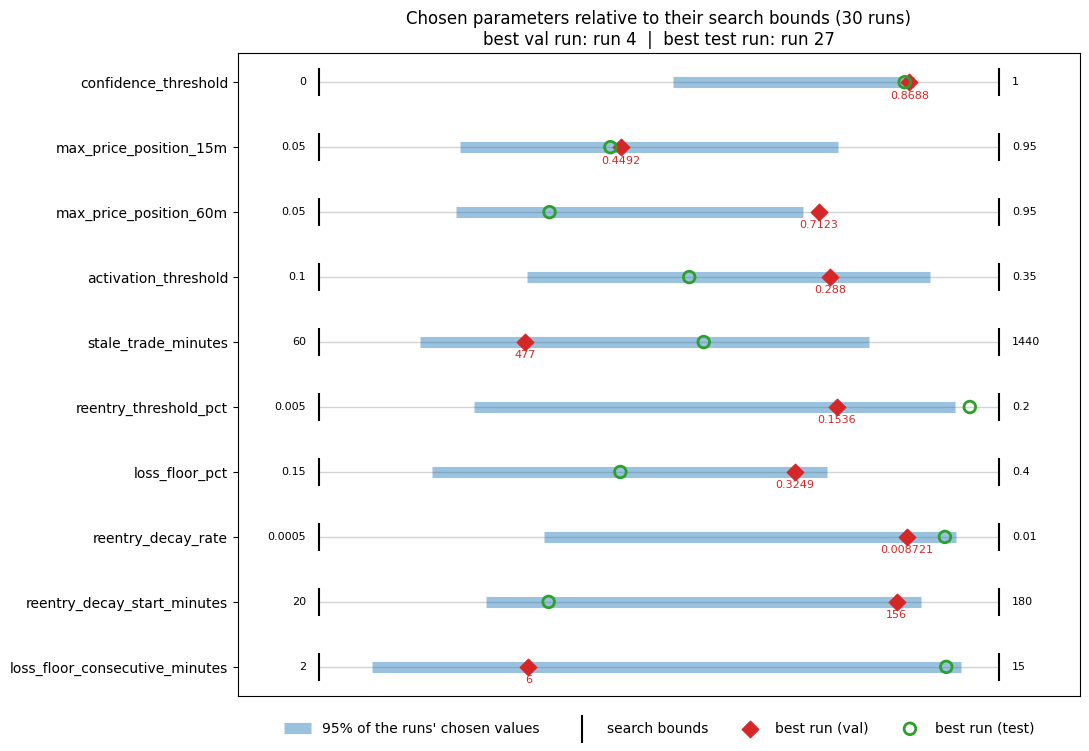

  A 95% range or the best value touching a bound means the optimiser wants to go further than allowed.
  Best val run = run 4; best test run = run 27 (green circles; shown for information — choosing by test is not an honest result).


In [ ]:
# ============================================================================
# RESULTS — all runs ranked by the VAL score; the best run's parameters; the
# parameter plot (95% range of the runs' choices, the best run, the search bounds)
# ============================================================================
RUNS = sorted(json.load(open(RUNS_FILE))['runs'], key=lambda r: r['run_idx'])[:N_RUNS]


def run_table(runs, which):
    """one row per run; diagnostics of the VAL or the TEST set."""
    rows = []
    for r in runs:
        d = r['val_diag'] if which == 'val' else r['test_diag']
        tt = d.get('total_trades', 0) or 0
        rows.append({'run': r['run_idx'] + 1, 'val $': r['val_score'], 'test $': r['test_score'],
                     'win rate %': 100 * d.get('win_rate_originals', np.nan),
                     'win rate re-entries %': 100 * d.get('win_rate_reentries', np.nan),
                     'total trades': int(tt),
                     'profitable coins %': d.get('pct_profitable', np.nan),
                     'untraded coins %': d.get('pct_untraded', np.nan),
                     'losing coins %': d.get('pct_unprofitable', np.nan),
                     'trades / coin': d.get('trades_per_coin', np.nan),
                     'avg net $ / trade': (d.get('total_pnl_usd', 0.0) / tt) if tt else np.nan})
    key = 'val $' if which == 'val' else 'test $'
    return pd.DataFrame(rows).sort_values(key, ascending=False).reset_index(drop=True)


def show(df):
    with pd.option_context('display.width', 250, 'display.max_columns', 20, 'display.float_format', lambda x: f"{x:.2f}"):
        print(df.to_string(index=False))


def print_params(r):
    for k, (lo, hi) in PARAM_BOUNDS.items():
        if k in r['params']:
            v = r['params'][k]
            print(f"    {k:<32} {v:>12.6g}     (search range {lo:g} - {hi:g})")
    for k, v in r['params'].items():
        if k not in PARAM_BOUNDS:
            print(f"    {k:<32} {v!s:>12}")


T = run_table(RUNS, 'val')
print("=" * 150)
print(f"  ALL {len(RUNS)} RUNS — ranked by the VAL score (all diagnostics on the VAL set; test $ = the run's "
      f"val-selected parameters on test)")
print("=" * 150)
show(T)
v, t = np.array([r['val_score'] for r in RUNS]), np.array([r['test_score'] for r in RUNS])
print(f"\n  mean over runs: val ${v.mean():.2f} ± {v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan:.2f}, "
      f"test ${t.mean():.2f} ± {t.std(ddof=1) / np.sqrt(len(t)) if len(t) > 1 else np.nan:.2f} (± = standard error)")
best = max(RUNS, key=lambda r: r['val_score'])
print("\n" + "=" * 150)
print(f"  BEST RUN ON VAL: run {best['run_idx'] + 1} — val ${best['val_score']:.2f}, test ${best['test_score']:.2f}  "
      f"(this run's test score is the honest result of picking the best val run)")
print("=" * 150)
print_params(best)

# ---- the parameter plot (shown, not saved) ----
names = [k for k in PARAM_BOUNDS if all(k in r['params'] for r in RUNS)]
best_test = max(RUNS, key=lambda r: r['test_score'])
same = best_test['run_idx'] == best['run_idx']
fig, ax = plt.subplots(figsize=(11, 0.6 * len(names) + 1.6))
for i, k in enumerate(names):
    lo, hi = PARAM_BOUNDS[k]
    vals = np.array([r['params'][k] for r in RUNS], dtype=float)
    q = (np.percentile(vals, [2.5, 97.5]) - lo) / (hi - lo)
    b = (best['params'][k] - lo) / (hi - lo)
    ax.plot([0, 1], [i, i], color='lightgray', lw=1, zorder=1)
    ax.plot(q, [i, i], color='tab:blue', lw=8, alpha=0.45, solid_capstyle='butt', zorder=2,
            label='95% of the runs\' chosen values' if i == 0 else None)
    ax.scatter([0, 1], [i, i], marker='|', s=400, color='black', zorder=3, label='search bounds' if i == 0 else None)
    ax.scatter([b], [i], marker='D', s=70, color='tab:red', zorder=4,
               label=('best run on val = best run on test' if same else 'best run (val)') if i == 0 else None)
    if not same:
        bt = (best_test['params'][k] - lo) / (hi - lo)
        ax.scatter([bt], [i], marker='o', s=70, facecolors='none', edgecolors='tab:green', linewidths=2, zorder=5,
                   label='best run (test)' if i == 0 else None)
    ax.text(-0.02, i, f"{lo:g}", ha='right', va='center', fontsize=8)
    ax.text(1.02, i, f"{hi:g}", ha='left', va='center', fontsize=8)
    ax.text(b, i + 0.28, f"{best['params'][k]:.4g}", ha='center', va='bottom', fontsize=8, color='tab:red')
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_xlim(-0.12, 1.12)
ax.set_xticks([])
ax.invert_yaxis()
ax.set_title(f"Chosen parameters relative to their search bounds ({len(RUNS)} runs)"
             + (f"\nthe best val run (run {best['run_idx'] + 1}) is also the best test run" if same else
                f"\nbest val run: run {best['run_idx'] + 1}  |  best test run: run {best_test['run_idx'] + 1}"))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False)
plt.tight_layout()
plt.show()
plt.close(fig)
print("  A 95% range or the best value touching a bound means the optimiser wants to go further than allowed.")
print(f"  Best val run = run {best['run_idx'] + 1}; best test run = run {best_test['run_idx'] + 1}"
      + (" — the SAME run (one marker)." if same else
         " (green circles; shown for information — choosing by test is not an honest result)."))

In [ ]:
# ============================================================================
# THE SAME, ranked by the TEST score (diagnostics on the TEST set) — for information
# ============================================================================
# Picking a run by its test score would be selection on test: the honest result is
# the test score of the run that was best on VAL (above). This view only shows how
# the runs did on the unseen coins.
TX = run_table(RUNS, 'test')
print("=" * 150)
print(f"  ALL {len(RUNS)} RUNS — ranked by the TEST score (all diagnostics on the TEST set)")
print("=" * 150)
show(TX)
best_t = max(RUNS, key=lambda r: r['test_score'])
print("\n" + "=" * 150)
print(f"  BEST RUN ON TEST: run {best_t['run_idx'] + 1} — test ${best_t['test_score']:.2f}, val ${best_t['val_score']:.2f}  "
      f"(for information only — choosing by test is not an honest result)")
print("=" * 150)
print_params(best_t)

  ALL 30 RUNS — ranked by the TEST score (all diagnostics on the TEST set)
 run  val $  test $  win rate %  win rate re-entries %  total trades  profitable coins %  untraded coins %  losing coins %  trades / coin  avg net $ / trade
  27  50.46   52.91       63.69                  62.68          1457               57.00              3.00           40.00          14.57               2.94
   2  51.86   52.31       60.77                  59.22          1463               50.00              2.00           48.00          14.63               3.34
  22  49.72   51.48       51.28                  54.54          1480               55.00              3.00           42.00          14.80               2.79
  17  47.78   50.83       54.87                  56.04          1427               52.00              2.00           46.00          14.27               3.01
  16  50.34   50.43       52.27                  53.31          1297               55.00              2.00           43.00          12.97   

In [ ]:
# ============================================================================
# EXPORT FOR THE LIVE PIPELINE — the two models, the tune reference
# distributions and the parameters of the best VAL run
# ============================================================================
# Writes OUT_DIR/live_artifacts/. Copy its files into live_pipeline/artifacts/:
#   move.ubj, direction.ubj     the two models of MODEL_DIR, unchanged (each file carries
#                               its feature list); the live scorer loads them by these names
#   ref_move.npy, ref_direction.npy, ref_combo.npy
#                               the sorted TUNE predictions P_move, P_dir and P_move x P_dir:
#                               the reference distributions of the percentile scores (the
#                               combo reference is the same one the sims above use)
#   best_params.json            the parameters of the run that is best on VAL (as in the results
#                               above; never chosen by test), used by the live bot as a whole
import shutil

LIVE_DIR = OUT_DIR / "live_artifacts"
LIVE_DIR.mkdir(parents=True, exist_ok=True)
for k, name in (('move', 'move.ubj'), ('dir', 'direction.ubj')):
    shutil.copy2(MODEL_FILES[k], LIVE_DIR / name)
    _back = load_model(LIVE_DIR / name)
    if list(_back.feature_names) != list(MODELS[k].feature_names):
        raise RuntimeError(f"{name}: the copied model's feature list differs from the loaded model's")
_rm = S['tune']['raw_move'].to_numpy()
_rd = S['tune']['raw_dir'].to_numpy()
_combo = _rm * _rd                       # the product exactly as above (`_ref`): same dtype, same rounding
_refs = {'ref_move': np.sort(_rm.astype(np.float64)), 'ref_direction': np.sort(_rd.astype(np.float64)),
         'ref_combo': np.sort(_combo.astype(np.float64))}
for name, v in _refs.items():
    np.save(LIVE_DIR / f"{name}.npy", v)
if not (np.array_equal(np.load(LIVE_DIR / "ref_combo.npy"), np.sort(np.asarray(_ref, dtype=np.float64)))
        and np.array_equal(to_percentile(_combo, np.load(LIVE_DIR / "ref_combo.npy")), S['tune']['combo'].to_numpy())):
    raise RuntimeError("the saved combo reference does not reproduce the sims' combo scores")

_runs = sorted(json.load(open(RUNS_FILE))['runs'], key=lambda r: r['run_idx'])[:N_RUNS]
_best = max(_runs, key=lambda r: r['val_score'])
json.dump({'run': _best['run_idx'] + 1, 'val_score': _best['val_score'], 'tune_score': _best.get('tune_score'),
           'test_score': _best.get('test_score'),
           'models': {'move': MODEL_FILES['move'].name, 'direction': MODEL_FILES['dir'].name},
           'params': _best['params']}, open(LIVE_DIR / "best_params.json", 'w'), indent=2)
print(f"✓ live artifacts -> {LIVE_DIR}/")
print(f"    models: {MODEL_FILES['move'].name} -> move.ubj, {MODEL_FILES['dir'].name} -> direction.ubj")
print(f"    reference distributions: {len(_rm):,} tune minutes")
print(f"    parameters: run {_best['run_idx'] + 1} (best of {len(_runs)} on val: val ${_best['val_score']:.2f}"
      + (f", test ${_best['test_score']:.2f}" if _best.get('test_score') is not None else "") + ")")
print("  Copy these files into live_pipeline/artifacts/ and restart the app.")